# Models > Classification and Regression Trees

<div class="alert alert-info">Estimate, prune, and interpret a classification tree</div>

<!-- pyrsm-teaching-note: roadmap -->
## Teaching Roadmap

Use this notebook to teach classification trees as a sequence of yes/no questions that sort observations into groups with a high or a low chance of the outcome of interest. Every number a tree reports can be recomputed from counts, which makes it a good first model for students: the probability in a node is the share of *Yes* in that node, and the Gini impurity is 2 × p × (1 − p). Students should (1) see that an unpruned tree fits noise, (2) prune it with cross-validation, (3) read the tree and its *split removes* column, (4) compare it with a logistic regression on a test set, and (5) know when to use a prior or a cost and margin. Trees do not need standardized variables.

In [1]:
import numpy as np
import polars as pl
import pyrsm as rsm
from pyrsm.model.perf import auc

In [2]:
## setup pyrsm for autoreload
%reload_ext autoreload
%autoreload 2
%aimport pyrsm

### Example: Titanic

The `titanic` data describe the survival status of 1,043 passengers on the Titanic. The principal source for data about Titanic passengers is the Encyclopedia Titanica. Which passengers were most likely to survive? We focus on four variables:

- `survived` = a factor with levels `Yes` and `No`
- `pclass` = Passenger Class (1st, 2nd, 3rd), a proxy for socio-economic status
- `sex` = Sex (female, male)
- `age` = Age in years

In [3]:
titanic = pl.read_parquet(
    "https://github.com/radiant-ai-hub/pyrsm/raw/refs/heads/main/examples/data/data/titanic.parquet"
)
titanic.head()

pclass,survived,sex,age,sibsp,parch,fare,name,cabin,embarked
enum,enum,enum,f64,i32,i32,f64,str,str,enum
"""1st""","""Yes""","""female""",29.0,0,0,211.337494,"""Allen, Miss. Elisabeth Walton""","""B5""","""Southampton"""
"""1st""","""Yes""","""male""",0.9167,1,2,151.550003,"""Allison, Master. Hudson Trevor""","""C22 C26""","""Southampton"""
"""1st""","""No""","""female""",2.0,1,2,151.550003,"""Allison, Miss. Helen Loraine""","""C22 C26""","""Southampton"""
"""1st""","""No""","""male""",30.0,1,2,151.550003,"""Allison, Mr. Hudson Joshua Crei""","""C22 C26""","""Southampton"""
"""1st""","""No""","""female""",25.0,1,2,151.550003,"""Allison, Mrs. Hudson J C (Bessi""","""C22 C26""","""Southampton"""


In [4]:
rsm.md(
    "https://raw.githubusercontent.com/radiant-ai-hub/pyrsm/refs/heads/main/examples/data/data/titanic_description.md"
)

## Titanic

This dataset describes the survival status of individual passengers on the Titanic. The titanic data frame does not contain information from the crew, but it does contain actual ages of (some of) the passengers. The principal source for data about Titanic passengers is the Encyclopedia Titanica. One of the original sources is Eaton & Haas (1994) Titanic: Triumph and Tragedy, Patrick Stephens Ltd, which includes a passenger list created by many researchers and edited by Michael A. Findlay.

## Variables

* survival - Survival (Yes, No)
* pclass - Passenger Class (1st, 2nd, 3rd)
* sex - Sex (female, male)
* age - Age in years
* sibsp - Number of Siblings/Spouses Aboard
* parch - Number of Parents/Children Aboard
* fare - Passenger Fare
* name - Name
* cabin - Cabin
* embarked - Port of Embarkation (Cherbourg, Queenstown, Southampton)

##  Notes

`pclass` is a proxy for socio-economic status (SES) 1st ~ Upper; 2nd ~ Middle; 3rd ~ Lower

Age is in Years; Fractional if Age less than One (1). If the Age is Estimated, it is in the form xx.5

With respect to the family relation variables (i.e. sibsp and parch) some relations were ignored.  The following are the definitions used for sibsp and parch.

Sibling:  Brother, Sister, Stepbrother, or Stepsister of Passenger Aboard Titanic
Spouse:   Husband or Wife of Passenger Aboard Titanic (Mistresses and Fiances Ignored)
Parent:   Mother or Father of Passenger Aboard Titanic
Child:    Son, Daughter, Stepson, or Stepdaughter of Passenger Aboard Titanic

Other family relatives excluded from this study include cousins, nephews/nieces, aunts/uncles, and in-laws. Some children travelled only with a nanny, therefore parch=0 for them.  As well, some travelled with very close friends or neighbors in a village, however, the definitions do not support such relations.

Note: Missing values and the `ticket` variable were removed from the data

## Related reading

<a href="http://phys.org/news/2012-07-shipwrecks-men-survive.html" target="_blank">In shipwrecks, men more likely to survive</a>

<!-- pyrsm-teaching-note: crtree-clf-how -->
### How a classification tree is grown

The tree starts with all 1,043 passengers in one node: 425 survived, so the predicted probability of `Yes` is 425 / 1,043 = 40.7%. How *mixed* a node is, is measured by the **Gini impurity**, 2 × p × (1 − p): 0 for a node where everyone survived (or no one did), 0.5 for a 50/50 node. The tree tries every explanatory variable and every possible split (e.g., `sex = female` vs `male`, or `age < 9.5` vs `age >= 9.5`) and picks the split that lowers the impurity the most, weighting each group by its size. It repeats this in each group.

`cp` (complexity parameter, default 0.001) and `minsplit` (default 2) decide when it stops. With the defaults the tree grows until the groups are tiny.

### Step 1: Grow a large tree

In [5]:
full = rsm.model.crtree(
    {"titanic": titanic},
    rvar="survived",
    lev="Yes",
    evar=["pclass", "sex", "age"],
)
full.cptable

CP,nsplit,rel error,xerror,xstd
f64,i64,f64,f64,f64
0.456471,0,1.0,1.0,0.037339
0.018824,1,0.543529,0.543529,0.031554
0.016471,2,0.524706,0.574118,0.032169
0.011765,4,0.491765,0.56,0.03189
0.007059,5,0.48,0.515294,0.03095
0.005882,9,0.447059,0.494118,0.030472
0.002353,11,0.435294,0.482353,0.030197
0.001765,21,0.411765,0.512941,0.030898
0.001569,36,0.371765,0.510588,0.030845


The full tree has 48 splits. For a classification tree `rel error` and `xerror` are the misclassification rate relative to the root (which misclassifies the 425 survivors by predicting `No` for everyone): on the estimation data the error keeps falling to 0.355, but the cross-validated error (`xerror`) is lowest at 11 splits (0.482) and rises again after that.

### Step 2: Prune the tree

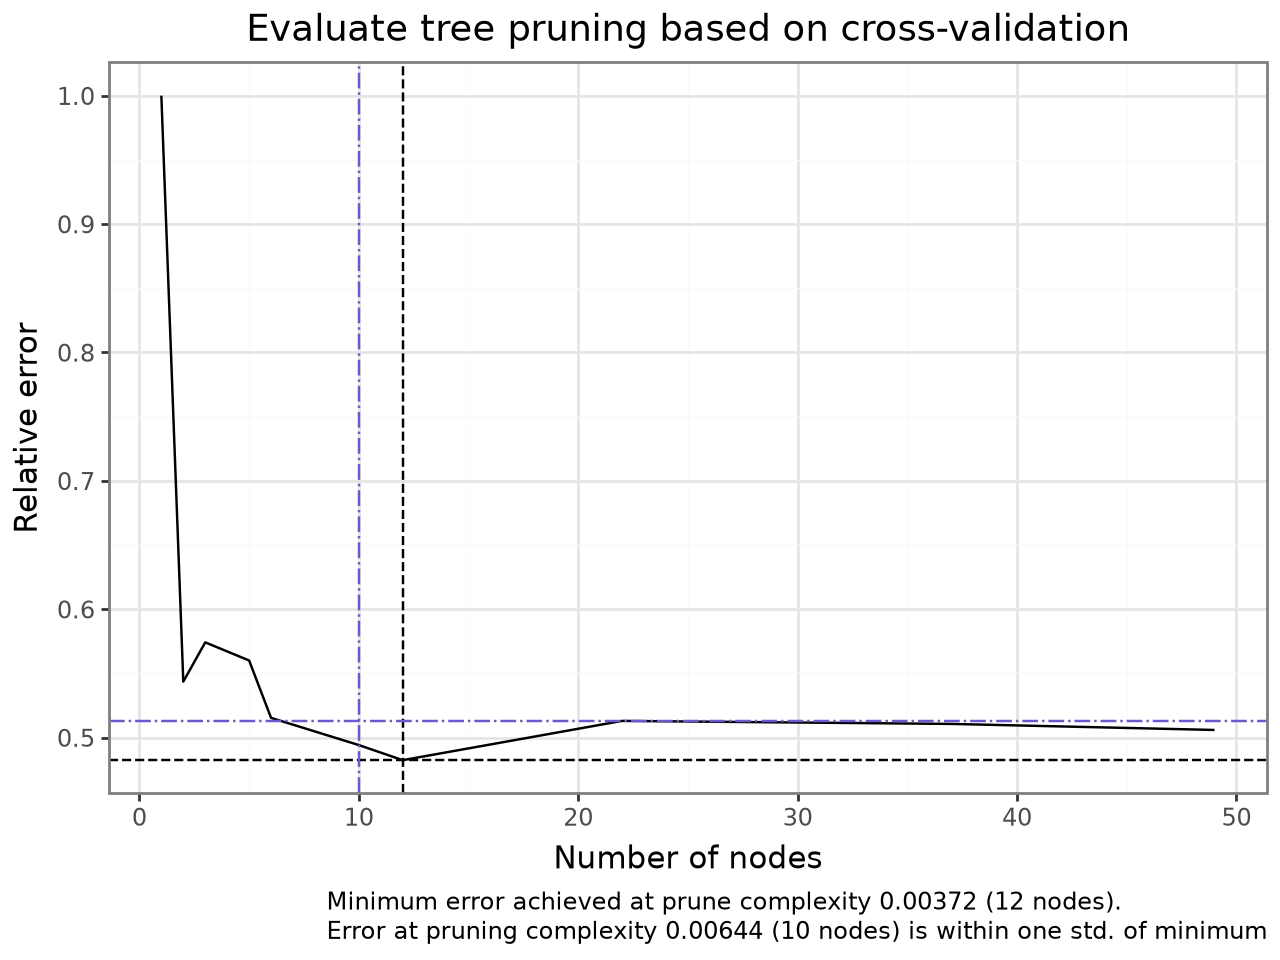

In [6]:
full.plot("prune")

<!-- pyrsm-teaching-note: crtree-clf-prune -->
The minimum cross-validated error is reached with 12 nodes (pruning complexity 0.00372). With 10 nodes (pruning complexity 0.00644) the error is within one standard error of the minimum: by the *one standard error rule* we prefer the smaller tree. We prune with `pcp=0.0065`.

Note that a tree is *grown* on the Gini impurity but *pruned* on the misclassification rate.

In [7]:
clf_tree = rsm.model.crtree(
    {"titanic": titanic},
    rvar="survived",
    lev="Yes",
    evar=["pclass", "sex", "age"],
    pcp=0.0065,
)
clf_tree.summary()

Classification tree
Data                 : titanic
Response variable    : survived
Level                : Yes in survived
Explanatory variables: pclass, sex, age
Complexity parameter : 0.001
Minimum observations : 2
Nr obs               : 1,043

node), split, n, loss, yval, (yprob)
      * denotes terminal node

  1) root 1043 425 No (0.40747843 0.59252157)  
    2) sex=female 386  96 Yes (0.75129534 0.24870466)  
      4) pclass=1st,2nd 234  16 Yes (0.93162393 0.06837607) *
      5) pclass=3rd 152  72 No (0.47368421 0.52631579)  
       10) age< 1.5 7   1 Yes (0.85714286 0.14285714) *
       11) age>=1.5 145  66 No (0.45517241 0.54482759)  
         22) age< 27.5 99  49 Yes (0.50505051 0.49494949)  
           44) age>=3.5 92  43 Yes (0.53260870 0.46739130)  
             88) age< 5.5 6   0 Yes (1.00000000 0.00000000) *
             89) age>=5.5 86  43 Yes (0.50000000 0.50000000)  
              178) age>=12 76  34 Yes (0.55263158 0.44736842) *
              179) age< 12 10   1 No (0.

Each line is a node: the split that leads to it, the number of passengers `n`, the number misclassified (`loss`), the predicted class (`yval`), and the probabilities of `Yes` and `No`. Terminal nodes are marked with `*`.

In [8]:
clf_tree.plot("tree")

graph LR
id1[sex] --- |female|id2[pclass<br><b>n:</b> 386<br><b>p:</b> 75.13%]
id2[pclass] --- |1st,2nd|id4[<b>n:</b> 234<br><b>p:</b> 93.16%]
id5[age] --- |< 1.5|id10[<b>n:</b> 7<br><b>p:</b> 85.71%]
id11[age] --- |< 27.5|id22[age<br><b>n:</b> 99<br><b>p:</b> 50.51%]
id22[age] --- |>=3.5|id44[age<br><b>n:</b> 92<br><b>p:</b> 53.26%]
id44[age] --- |< 5.5|id88[<b>n:</b> 6<br><b>p:</b> 100.00%]
id89[age] --- |>=12|id178[<b>n:</b> 76<br><b>p:</b> 55.26%]
id3[age] --- |< 9.5|id6[pclass<br><b>n:</b> 43<br><b>p:</b> 58.14%]
id6[pclass] --- |1st,2nd|id12[<b>n:</b> 14<br><b>p:</b> 100.00%]
id1[sex] --- |male|id3[age<br><b>n:</b> 657<br><b>p:</b> 20.55%]
id2[pclass] --- |3rd|id5[age<br><b>n:</b> 152<br><b>p:</b> 47.37%]
id5[age] --- |>=1.5|id11[age<br><b>n:</b> 145<br><b>p:</b> 45.52%]
id11[age] --- |>=27.5|id23[<b>n:</b> 46<br><b>p:</b> 34.78%]
id22[age] --- |< 3.5|id45[<b>n:</b> 7<br><b>p:</b> 14.29%]
id44[age] --- |>=5.5|id89[age<br><b>n:</b> 86<br><b>p:</b> 50.00%]
id89[age] --- |< 12|id179[<b>n:</b> 10<br><b>p:</b> 10.00%]
id3[age] --- |>=9.5|id7[<b>n:</b> 614<br><b>p:</b> 17.92%]
id6[pclass] --- |3rd|id13[<b>n:</b> 29<br><b>p:</b> 37.93%]
classDef default fill:none, bg:none, stroke-width:0px;
      classDef leaf fill:#9ACD32,stroke:#333,stroke-width:1px;
      classDef chance fill:#FF8C00,stroke:#333,stroke-width:1px;
      classDef chance_with_cost fill:#FF8C00,stroke:#333,stroke-width:3px,stroke-dasharray:4,5;
      classDef decision fill:#9ACD32,stroke:#333,stroke-width:1px;
      classDef decision_with_cost fill:#9ACD32,stroke:#333,stroke-width:3px,stroke-dasharray:4,5;
      class id4,id10,id88,id178,id12,id23,id45,id179,id7,id13 leaf;
click id1 callback "<b>n:</b> 1,043<br><b>p:</b> 40.75%"
click id2 callback "<b>n:</b> 386<br><b>p:</b> 75.13%"
click id5 callback "<b>n:</b> 152<br><b>p:</b> 47.37%"
click id11 callback "<b>n:</b> 145<br><b>p:</b> 45.52%"
click id22 callback "<b>n:</b> 99<br><b>p:</b> 50.51%"
click id44 callback "<b>n:</b> 92<br><b>p:</b> 53.26%"
click id89 callback "<b>n:</b> 86<br><b>p:</b> 50.00%"
click id3 callback "<b>n:</b> 657<br><b>p:</b> 20.55%"
click id6 callback "<b>n:</b> 43<br><b>p:</b> 58.14%"

<!-- pyrsm-teaching-note: crtree-clf-read -->
### Reading the tree: women and children first

- The first split is on `sex`. Of the 386 women, 290 survived (75.1%); of the 657 men, 135 (20.5%).
- Women in 1st and 2nd class almost all survived: 218 of 234 (93.2%). For women in 3rd class it was a coin flip (72 of 152, 47.4%), and the tree splits them further by age.
- For men, age comes first: 25 of the 43 boys younger than 9.5 survived (58.1%), and all 14 boys in 1st and 2nd class did. Of the 614 men aged 9.5 or older only 110 survived (17.9%).

Some leaves are very small and their probabilities extreme. Among women in 3rd class, all 6 girls aged 3.5 to 5.5 survived, but only 1 of 10 aged 5.5 to 12. Is that a real pattern, or noise that the 1 standard error rule did not remove? With so few passengers the data cannot tell, and a different sample would likely give different cut-offs. Use judgement: a larger `pcp` removes these splits.

### The node table: recompute everything from counts

`node_table()` lists every node with its counts (`Yes`, `No`), the probability of `Yes` (`prediction`), and `removed`: how much the node's split lowers the impurity, as a share of the impurity at the root.

In [9]:
nt = clf_tree.node_table()
nt.select("node", "split", "leaf", "n", "counts", "prediction", "removed")

node,split,leaf,n,counts,prediction,removed
i64,str,bool,i64,list[i64],f64,f64
1,"""""",false,1043,"[425, 618]",0.407478,0.287652
2,"""sex = female""",false,386,"[290, 96]",0.751295,0.076735
4,"""pclass in 1st, 2nd""",true,234,"[218, 16]",0.931624,null
5,"""pclass = 3rd""",false,152,"[72, 80]",0.473684,0.004285
10,"""age < 1.5""",true,7,"[6, 1]",0.857143,null
11,"""age >= 1.5""",false,145,"[66, 79]",0.455172,0.003083
22,"""age < 27.5""",false,99,"[50, 49]",0.505051,0.003924
44,"""age >= 3.5""",false,92,"[49, 43]",0.532609,0.005568
88,"""age < 5.5""",true,6,"[6, 0]",1.0,null


In [10]:
def gini(yes, n):
    p = yes / n
    return 2 * p * (1 - p)


root, female, male = gini(425, 1043), gini(290, 386), gini(135, 657)
print(f"root:   p = {425 / 1043:.3f}, Gini = {root:.3f}")
print(f"female: p = {290 / 386:.3f}, Gini = {female:.3f}")
print(f"male:   p = {135 / 657:.3f}, Gini = {male:.3f}")

# n x Gini: parent minus its two children, as a share of the root
removes = (1043 * root - 386 * female - 657 * male) / (1043 * root)
print(f"The sex split removes {removes:.1%} of the impurity at the root")

root:   p = 0.407, Gini = 0.483
female: p = 0.751, Gini = 0.374
male:   p = 0.205, Gini = 0.327
The sex split removes 28.8% of the impurity at the root


The `sex` split lowers the impurity from 1,043 × 0.483 = 503.7 to 386 × 0.374 + 657 × 0.327 = 358.8, removing 28.8% of the impurity at the root. The other splits remove much less: the `pclass` split among women 7.7%, the `age` split among men 2.6%, and the `pclass` split among boys 1.4%. The age splits among women in 3rd class each remove less than 1%.

### Which variables matter?

Permutation importance shuffles one variable at a time and measures how much the area under the ROC curve (AUC) drops.

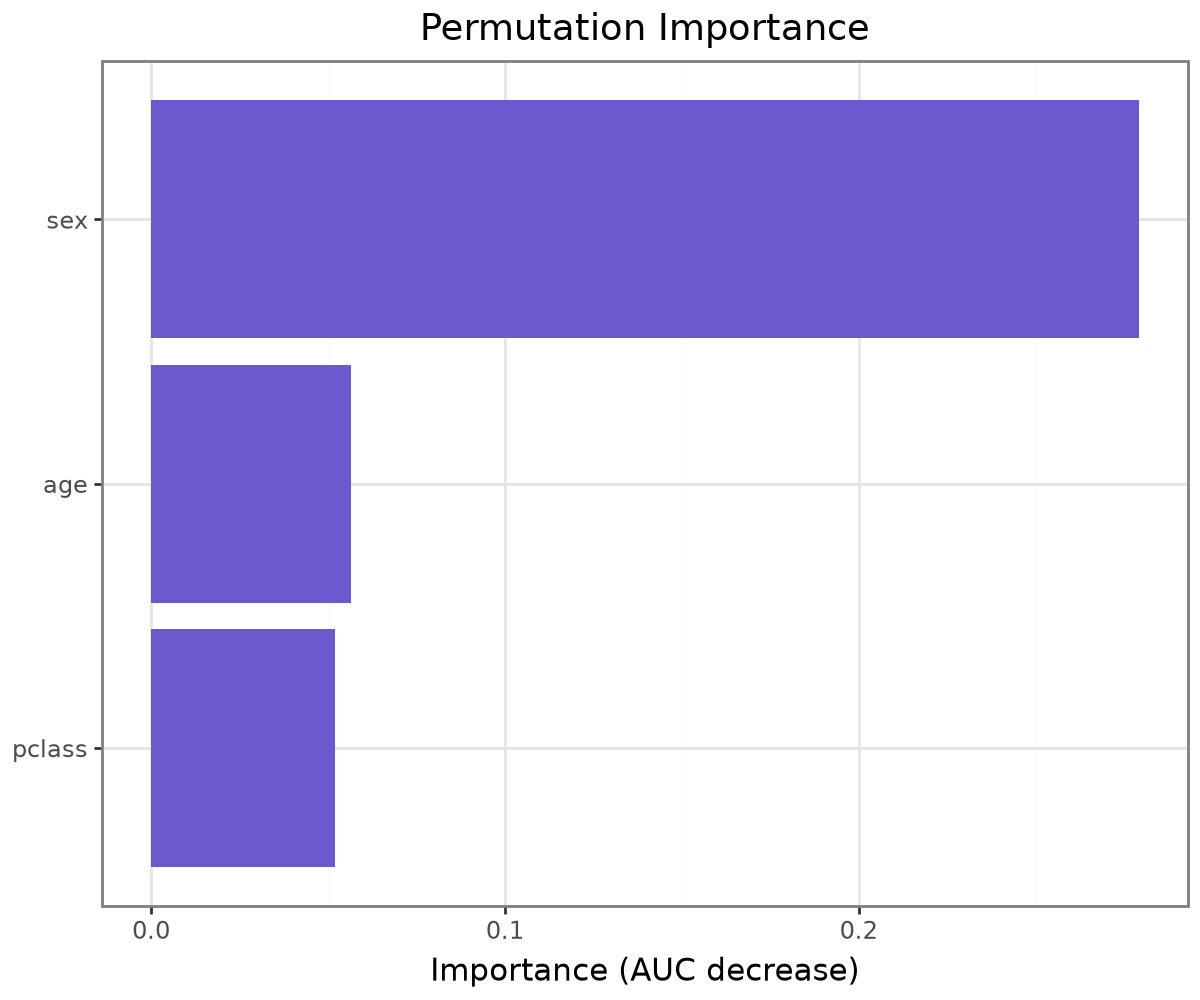

In [11]:
clf_tree.plot("pip")

Shuffling `sex` lowers the AUC by 0.279; `age` (0.057) and `pclass` (0.052) matter much less, and about equally.

<!-- pyrsm-teaching-note: crtree-clf-pdp -->
### Prediction plots and partial dependence

A prediction plot varies one variable and keeps the others at their average or most common level: here a man (`sex`) in 3rd class (`pclass`), and an age of 29.8. The interaction plots show one variable for each level of another.

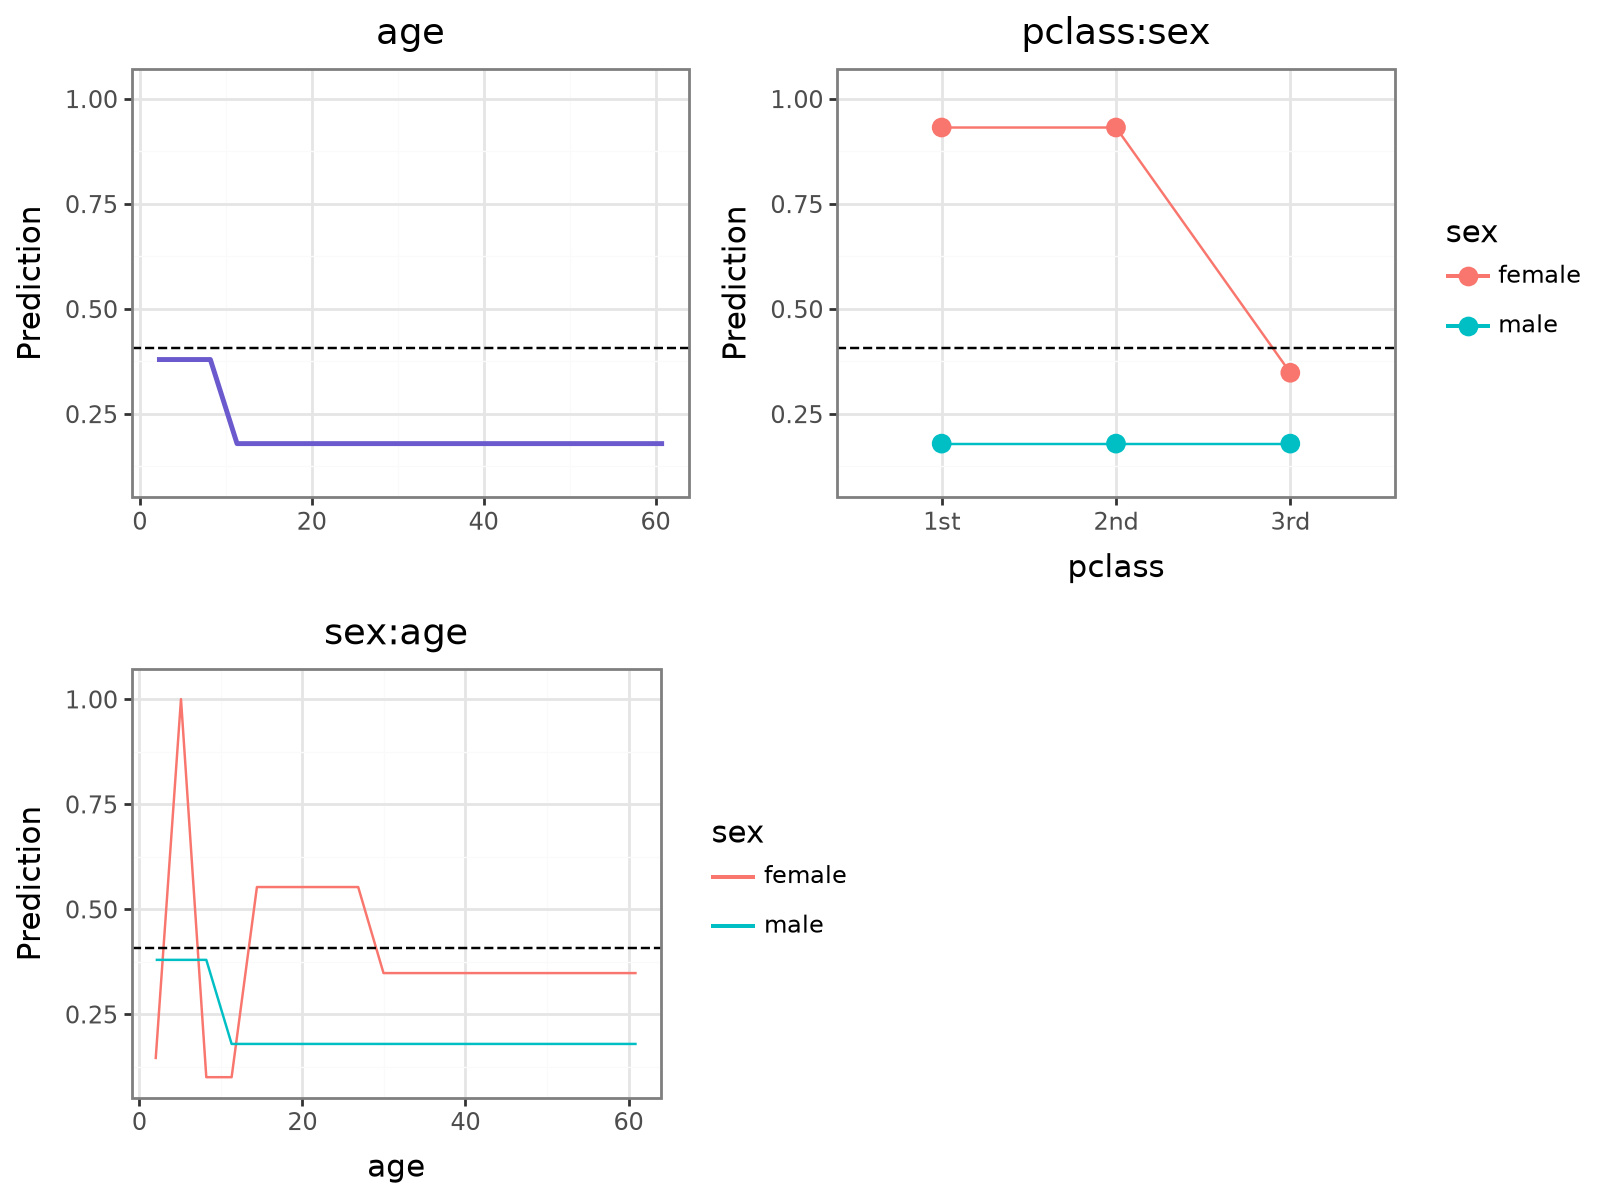

In [12]:
clf_tree.plot("pred", incl=["age"], incl_int=["pclass:sex", "sex:age"])

- `age`: for a man in 3rd class the probability drops from 37.9% to 17.9% at age 9.5.
- `pclass:sex`: at the average age, class matters a lot for women (93.2% in 1st and 2nd, 34.8% in 3rd) and not at all for men (17.9%): an interaction.
- `sex:age`: the line for women (in 3rd class) jumps up and down with age. These are the small, noisy leaves we saw above; a smooth model like logistic regression could not produce this pattern.

The partial dependence plot sets a variable to each value for every passenger and averages the predictions. With `ice=True` it also draws the lines for individual passengers (a sample of 100):

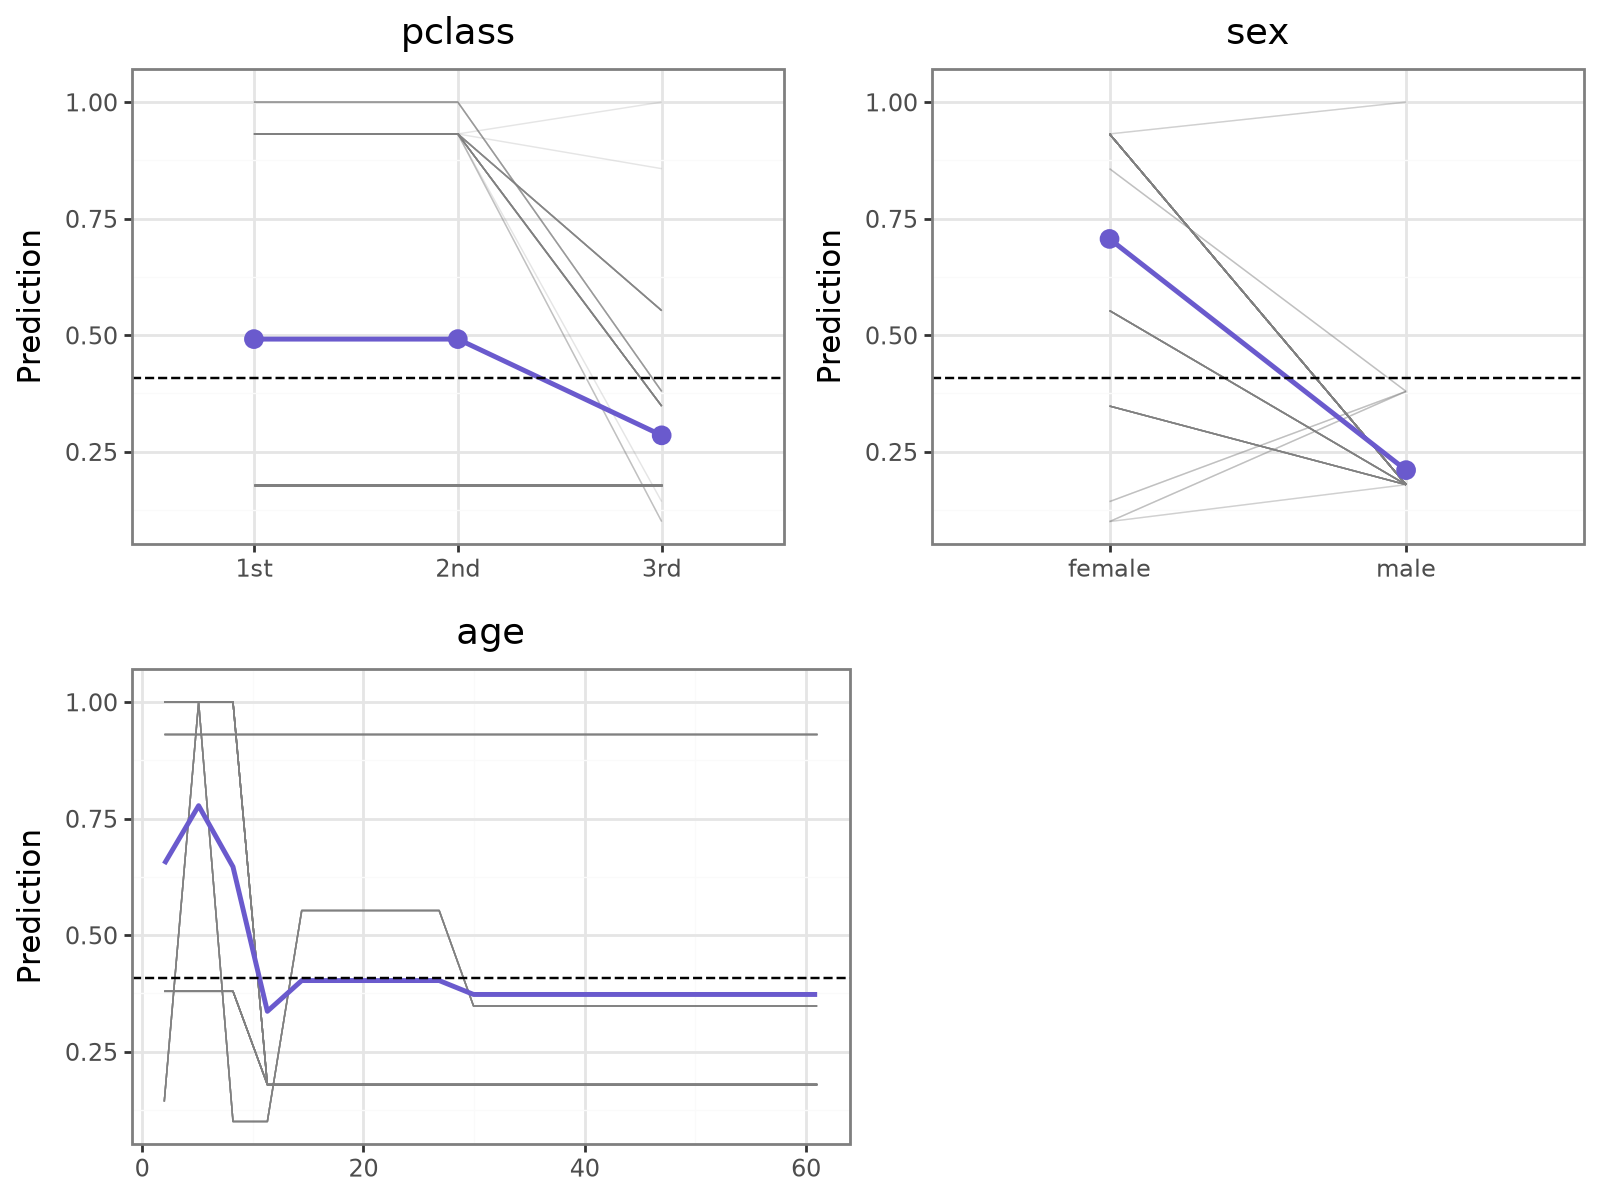

In [13]:
clf_tree.plot("pdp", ice=True)

On average, women had a much higher predicted probability of survival than men, and 3rd class passengers a lower one than 1st and 2nd. The ICE lines show that these averages hide very different groups: for `pclass`, some passengers' lines are flat (men older than 9.5, at 17.9% in every class) and others drop steeply in 3rd class (women).

### Predictions

Predicted probabilities for a 5- and a 30-year-old woman and man in each class:

In [14]:
clf_tree.predict(cmd={"pclass": ["1st", "2nd", "3rd"], "sex": ["female", "male"], "age": [5, 30]})

pclass,sex,age,prediction
enum,enum,f64,f64
"""1st""","""female""",5.0,0.931624
"""1st""","""female""",30.0,0.931624
"""1st""","""male""",5.0,1.0
"""1st""","""male""",30.0,0.179153
"""2nd""","""female""",5.0,0.931624
"""2nd""","""female""",30.0,0.931624
"""2nd""","""male""",5.0,1.0
"""2nd""","""male""",30.0,0.179153
"""3rd""","""female""",5.0,1.0


Women in 1st and 2nd class: 93.2% regardless of age. Boys of 5 in 1st and 2nd class: 100% (all 14 in the data survived). A 30-year-old man has a 17.9% chance in every class. A probability of 100% (or 0%) from a small leaf should not be taken literally.

<!-- pyrsm-teaching-note: crtree-clf-compare -->
### Tree or logistic regression?

Logistic regression with the same three variables:

In [15]:
lr = rsm.model.logistic({"titanic": titanic}, rvar="survived", lev="Yes", evar=["pclass", "sex", "age"])
y = (titanic["survived"] == "Yes").to_numpy().astype(int)
p_tree = clf_tree.predict(titanic)["prediction"].to_numpy()
p_lr = lr.predict(titanic)["prediction"].to_numpy()
print(f"AUC       tree: {auc(y, p_tree):.3f}  logistic: {auc(y, p_lr):.3f}")
print(f"Accuracy  tree: {np.mean((p_tree > 0.5) == y):.3f}  logistic: {np.mean((p_lr > 0.5) == y):.3f}")

AUC       tree: 0.828  logistic: 0.839
Accuracy  tree: 0.818  logistic: 0.784


On the data the models were estimated on, the tree has a lower AUC (0.828 vs 0.839) but a higher accuracy at a 0.5 cut-off (81.8% vs 78.4%). Both are in-sample numbers, and the tree was pruned on these same data. A fair comparison estimates both models on a *training* sample and scores them on a *test* sample neither has seen:

In [16]:
rng = np.random.default_rng(1234)
titanic = titanic.with_columns(training=pl.Series((rng.random(titanic.height) < 0.7).astype(int)))
train = titanic.filter(pl.col("training") == 1)
test = titanic.filter(pl.col("training") == 0)
y_test = (test["survived"] == "Yes").to_numpy().astype(int)

tree_tr = rsm.model.crtree(
    {"train": train}, rvar="survived", lev="Yes", evar=["pclass", "sex", "age"], pcp=0.0065
)
lr_tr = rsm.model.logistic({"train": train}, rvar="survived", lev="Yes", evar=["pclass", "sex", "age"])
print(f"Training: {train.height} rows, test: {test.height} rows")
print(f"Test AUC  tree: {auc(y_test, tree_tr.predict(test)['prediction'].to_numpy()):.3f}")
print(f"Test AUC  logistic: {auc(y_test, lr_tr.predict(test)['prediction'].to_numpy()):.3f}")

Training: 741 rows, test: 302 rows
Test AUC  tree: 0.789
Test AUC  logistic: 0.830


On the 302 test passengers the logistic regression ranks survivors better (AUC 0.830) than the tree (0.789). The tree's main advantages are that it is easy to explain and finds interactions on its own; its predictions come from small groups and change with the sample. Random forests and gradient boosted trees average or combine many trees and usually predict much better than a single tree (see the [random forest classification notebook](model-rforest-classification.ipynb)). Use *Model > Evaluate classification* or `rsm.model.evalbin` to compare models on a test set with gains, lift, and profit curves.

<!-- pyrsm-teaching-note: crtree-clf-prior -->
### Prior

When the level of interest is rare (say 2% of customers respond to an offer), a tree often finds no split worth making: predicting `No` for everyone is already 98% accurate. A **prior** tells the tree how much weight to give each class while growing it. `prior=0.5` weighs `Yes` and `No` equally, which helps the tree find splits for a small group. The probabilities it reports are adjusted back to the share of `Yes` in the data, so they can still be used as probabilities.

Survival is not rare in these data (40.7%), but the effect is easy to see:

In [17]:
rsm.model.crtree(
    {"titanic": titanic},
    rvar="survived",
    lev="Yes",
    evar=["pclass", "sex", "age"],
    pcp=0.0065,
    prior=0.5,
).summary()

Classification tree
Data                 : titanic
Response variable    : survived
Level                : Yes in survived
Explanatory variables: pclass, sex, age
Complexity parameter : 0.001
Minimum observations : 2
Priors               : 0.5
Adjusted prob.       : True
Nr obs               : 1,043

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 1043 521.50000 No (0.4074784 0.5925216)  
  2) sex=female 386  81.00971 Yes (0.7512953 0.2487047) *
  3) sex=male 657 165.65290 No (0.2054795 0.7945205)  
    6) age< 9.5 43  15.18932 Yes (0.5813953 0.4186047) *
    7) age>=9.5 614 134.97650 No (0.1791531 0.8208469) *


The probabilities in the nodes are unchanged (75.1% for women, 58.1% for boys younger than 9.5), but with the prior the misclassification rate is measured on a different scale, so the same `pcp` now gives a 3-node tree. Check the prune plot again after setting a prior. Leave the prior blank (`None`) to grow the tree on the class shares in the data; then every number in the node table can be recomputed from the counts.

### Cost and margin

If the tree is used to decide whom to target, the cost of a wrong decision is not the same in both directions. Targeting a customer costs `cost`; a customer who responds brings in `margin`. Targeting is profitable when the probability of a response is larger than the *break-even* rate, `cost / margin`. With `cost` and `margin` the tree is grown and pruned on these losses instead of the misclassification rate. To illustrate with the titanic data, `cost=1` and `margin=3` give a break-even of 1/3:

In [18]:
rsm.model.crtree(
    {"titanic": titanic},
    rvar="survived",
    lev="Yes",
    evar=["pclass", "sex", "age"],
    pcp=0.0065,
    cost=1,
    margin=3,
).summary()

Classification tree
Data                 : titanic
Response variable    : survived
Level                : Yes in survived
Explanatory variables: pclass, sex, age
Complexity parameter : 0.001
Minimum observations : 2
Cost:Margin          : 1 : 3
Nr obs               : 1,043

node), split, n, loss, yval, (yprob)
      * denotes terminal node

  1) root 1043 618 Yes (0.4074784 0.5925216)  
    2) sex=female 386  96 Yes (0.7512953 0.2487047) *
    3) sex=male 657 270 No (0.2054795 0.7945205)  
      6) age< 9.5 43  18 Yes (0.5813953 0.4186047) *
      7) age>=9.5 614 220 No (0.1791531 0.8208469)  
       14) pclass=1st 148  98 Yes (0.3378378 0.6621622)  
         28) age< 54.5 120  73 Yes (0.3916667 0.6083333)  
           56) age< 36.5 56  30 Yes (0.4642857 0.5357143) *
           57) age>=36.5 64  42 No (0.3281250 0.6718750)  
            114) age>=47.5 23  11 Yes (0.5217391 0.4782609) *
            115) age< 47.5 41  18 No (0.2195122 0.7804878) *
         29) age>=54.5 28   6 No (0.1071

Every node with a probability of `Yes` above 1/3 now predicts `Yes`, the root (40.7%) included. The tree also splits the men older than 9.5 by class: in 1st class (33.8%, just above 1/3) they are predicted `Yes` and split further by age, while men in 2nd and 3rd class (12.9%) are predicted `No`. Use either a prior or a cost and margin, not both.

<!-- pyrsm-teaching-note: crtree-clf-takeaways -->
### Takeaways

- Grow a large tree, then prune it with the prune plot and the one standard error rule (`pcp` or `nodes`).
- Every number in the tree can be recomputed from counts: p = Yes / n, Gini = 2 × p × (1 − p), and *removed* compares n × Gini of a node with its two children.
- Small leaves with probabilities of 0% or 100% are usually noise.
- Trees find interactions on their own and are easy to explain, but a single tree often predicts worse on new data than a logistic regression or a forest. Compare models on a test set.